# Étape 7 : tests et validation de l'agent

Objectif : vérifier que l'agent se comporte correctement sur des requêtes **variées** (texte, figure,
image seule, image + question, hybride, information absente, salutation, langue), et **mesurer** son
comportement plutôt que de se fier à une impression.

Pour chaque cas, on relève :
- **l'outil a-t-il été appelé ?** (et il ne doit PAS l'être pour une salutation) ;
- **les arguments** : `type_resultat` choisi, requête bien **traduite en anglais** ;
- **les pages récupérées** : contiennent-elles la bonne page ?
- **la réponse finale**, avec un contrôle par mots-clés attendus ;
- un **verdict** : ✅ conforme, ⚠️ partiellement conforme, ❌ non conforme.

Les verdicts sont calculés automatiquement à partir de critères écrits **avant** l'exécution,
puis discutés dans l'analyse finale.

## Imports

Même en-tête que les autres notebooks. `pymupdf` sert à fabriquer l'image de requête, `pandas` au tableau final.

In [1]:
import sys, time, re
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pymupdf
import pandas as pd
from PIL import Image
from IPython.display import display

from src.agent import interroger_agent, MODELE_LLM
print("Modèle testé :", MODELE_LLM)

c:\Users\aliel\Downloads\tp3_rag\rag-multimodal-agentique_tp3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modèle testé : qwen3-vl:4b


## Image de requête : la figure 1 rendue depuis le PDF

Pour tester les requêtes **image**, il faut une image qui joue le rôle d'une photo envoyée par l'utilisateur.
On **rend** la zone de la figure 1 (page 3) avec `get_pixmap` plutôt que de réutiliser le fichier extrait à
l'étape 1 : l'image obtenue n'est pas identique à celle indexée (résolution, cadrage), comme dans un cas réel.
La zone (`clip`) est la position de l'image sur la page, donnée par `get_image_info`.

resultats_pdf\requetes\figure1_rendue.png 457 x 672


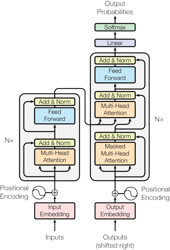

In [2]:
REQUETES_DIR = ROOT / "resultats_pdf" / "requetes"
REQUETES_DIR.mkdir(parents=True, exist_ok=True)

doc = pymupdf.open(ROOT / "data" / "attention_is_all_you_need.pdf")
page = doc[2]                                        # page 3 (index 0)
zone = pymupdf.Rect(page.get_image_info()[0]["bbox"])
pix = page.get_pixmap(clip=zone, dpi=150)
IMAGE_FIGURE1 = REQUETES_DIR / "figure1_rendue.png"
pix.save(IMAGE_FIGURE1)
print(IMAGE_FIGURE1.relative_to(ROOT), pix.width, "x", pix.height)

with Image.open(IMAGE_FIGURE1) as img:
    apercu = img.convert("RGB"); apercu.thumbnail((250, 250)); display(apercu)

## Outils de test

`tester(...)` exécute l'agent (avec la trace ReAct affichée), puis compare le résultat aux **attentes** :
- `outil` : l'outil doit-il être appelé ?
- `pages` : au moins une de ces pages doit être dans les sources récupérées ;
- `mots` : au moins un de ces mots (ou expressions régulières) doit apparaître dans la réponse ;
- `image` : une figure doit-elle faire partie des sources ?

Le verdict : ❌ si l'usage de l'outil est faux, ✅ si tout est conforme, ⚠️ sinon.
On vérifie aussi que la requête envoyée à l'outil est en anglais (heuristique : pas de mots français courants ni d'accents).

In [3]:
MOTS_FR = re.compile(r"[éèàùçêô]|\b(le|la|les|des|du|une|pourquoi|quel|quelle|comment|est)\b", re.I)
resultats_tests = []

def tester(num, nom, texte=None, image=None, outil=True, pages=(), mots=(), image_attendue=False):
    print(f"===== Cas {num} : {nom} =====")
    print("Question :", texte, "| image :", Path(image).name if image else None)
    debut = time.time()
    r = interroger_agent(texte=texte, image=image)
    duree = time.time() - debut

    appele = len(r["appels_outils"]) > 0
    pages_trouvees = sorted({s["page"] for s in r["sources"]})
    types = sorted({a.get("type_resultat", "tous") for a in r["appels_outils"]})
    en_anglais = all(not MOTS_FR.search(a.get("requete", "")) for a in r["appels_outils"])
    ok_pages = not pages or any(p in pages_trouvees for p in pages)
    ok_mots = not mots or any(re.search(m, r["reponse"], re.I) for m in mots)
    ok_image = not image_attendue or len(r["images"]) > 0

    if appele != outil:
        verdict = "❌"
    elif ok_pages and ok_mots and ok_image and (not appele or en_anglais):
        verdict = "✅"
    else:
        verdict = "⚠️"

    ligne = {
        "cas": num, "test": nom, "outil appelé": appele, "nb appels": len(r["appels_outils"]),
        "type_resultat": ", ".join(types) or "-",
        "requête(s)": " | ".join(a.get("requete", "") for a in r["appels_outils"]) or "-",
        "requête en anglais": en_anglais if appele else "-",
        "pages récupérées": pages_trouvees, "figure récupérée": len(r["images"]) > 0,
        "pages OK": ok_pages, "mots-clés OK": ok_mots, "durée (s)": round(duree),
        "verdict": verdict,
    }
    resultats_tests.append({**ligne, "réponse": r["reponse"]})
    print(f"\n➡️ Verdict : {verdict} | outil={appele} (attendu {outil}) | pages {pages_trouvees} "
          f"| pages OK={ok_pages} | mots-clés OK={ok_mots} | figure OK={ok_image} | {duree:.0f} s")
    return r

## Cas 1 : question texte

**Pourquoi diviser par √d_k ?** La réponse est page 4 : sans ce facteur, les produits scalaires deviennent
grands et poussent le softmax dans des zones à **gradients très faibles**.
Attendu : outil appelé, `type_resultat="texte"`, page 4, réponse qui parle de softmax / gradients.

In [4]:
r = tester(1, "Texte : division par √d_k",
           texte="Pourquoi divise-t-on les produits scalaires par la racine carrée de d_k dans l'attention ?",
           pages=[4], mots=[r"softmax", r"gradient"])

===== Cas 1 : Texte : division par √d_k =====
Question : Pourquoi divise-t-on les produits scalaires par la racine carrée de d_k dans l'attention ? | image : None


KeyboardInterrupt: 

## Cas 2 : question sur une figure

**Figure 2** (page 4) : à gauche la *scaled dot-product attention*, à droite la *multi-head attention*.
Attendu : `type_resultat` = `"tous"` ou `"image"`, une figure de la page 4 récupérée **et montrée** au modèle,
réponse qui décrit les éléments visibles (MatMul, SoftMax, Concat, h têtes...).

In [5]:
r = tester(2, "Figure 2 : scaled dot-product + multi-head",
           texte="Explique la figure 2 de l'article : la scaled dot-product attention et la multi-head attention.",
           pages=[4], mots=[r"softmax", r"concat", r"matmul"], image_attendue=True)

===== Cas 2 : Figure 2 : scaled dot-product + multi-head =====
Question : Explique la figure 2 de l'article : la scaled dot-product attention et la multi-head attention. | image : None


KeyboardInterrupt: 

## Cas 3 : requête image seule

L'utilisateur envoie la figure 1 **sans question**. Le modèle vision doit reconnaître l'architecture du
Transformer, puis (idéalement) chercher dans l'article pour relier l'image au texte.
Remarque : l'outil ne prend que du **texte** ; c'est donc le LLM qui « traduit » l'image en requête.
Attendu : outil appelé, page 3 (figure 1) dans les sources, réponse qui parle d'encodeur/décodeur.

In [ ]:
r = tester(3, "Image seule (figure 1)", image=IMAGE_FIGURE1,
           pages=[3], mots=[r"encod", r"d[ée]cod", r"transformer"])

## Cas 4 : image + question

Même image, avec une question précise. Le LLM doit combiner **ce qu'il voit** (N×, deux piles, flèches
de l'encodeur vers le décodeur) et **ce qu'il récupère** (section 3.1, pages 2-3 : 6 couches, deux sous-couches,
masquage dans le décodeur).
Attendu : outil appelé, page 2 ou 3, réponse qui parle de l'encodeur ET du décodeur.

In [ ]:
r = tester(4, "Image + question : encodeur/décodeur",
           texte="Explique le rôle de l'encodeur et du décodeur dans cette figure.", image=IMAGE_FIGURE1,
           pages=[2, 3], mots=[r"(?=.*encod)(?=.*d[ée]cod)"])

## Cas 5 : question hybride texte + figures

Deux notions à combiner, dont une illustrée par une figure (multi-head, figure 2) et l'autre uniquement
décrite dans le texte (positional encoding, page 6 : sinus et cosinus).
Attendu : `type_resultat="tous"`, éventuellement **plusieurs appels** (une notion par appel), pages 4-5 et 6,
réponse qui parle des deux.

In [ ]:
r = tester(5, "Hybride : multi-head vs positional encoding",
           texte="Compare la multi-head attention et le positional encoding, en t'appuyant sur les figures de l'article.",
           pages=[4, 5, 6], mots=[r"(?=.*(sinus|sine|cos))(?=.*(t[êe]te|head))"], image_attendue=True)

## Cas 6 : information absente

GPT-4 et le benchmark MMLU sont **postérieurs** à l'article (2017). Le LLM peut les connaître, mais
il doit chercher, constater que les sources n'en parlent pas, et **le dire** au lieu d'inventer.
Attendu : outil appelé, réponse qui dit clairement que l'information est absente.

In [ ]:
r = tester(6, "Information absente (MMLU de GPT-4)",
           texte="Quel est le score MMLU de GPT-4 selon l'article ?",
           mots=[r"absent", r"ne (mentionne|contient|parle|donne|fournit|pr[ée]sente)", r"n'est pas", r"aucune",
                 r"pas d'information", r"ne figure pas"])

## Cas 7 : salutation

Attendu : **aucun** appel d'outil, réponse brève. C'est le comportement agentique : le LLM **décide**
que la recherche est inutile.

In [ ]:
r = tester(7, "Salutation", texte="Bonjour, comment ça va ?", outil=False)

## Cas 8 : même question en français et en anglais

La base est en anglais. Une question en français doit donner le **même résultat** qu'en anglais, car le LLM
traduit la requête. On demande le nombre de têtes d'attention (réponse : **h = 8**, page 5).
Attendu pour les deux : outil appelé, requête en anglais, page 5, réponse contenant « 8 » (en français).

In [ ]:
r_fr = tester("8a", "Même question en français", texte="Combien de têtes d'attention utilise le modèle de base ?",
              pages=[5], mots=[r"\b8\b|huit"])

In [ ]:
r_en = tester("8b", "Même question en anglais", texte="How many attention heads does the base model use?",
              pages=[5], mots=[r"\b8\b|eight|huit"])

Comparaison des deux langues : requêtes envoyées à l'outil et pages récupérées.

In [ ]:
for nom, res in [("FR", r_fr), ("EN", r_en)]:
    print(f"{nom} | requêtes : {[a['requete'] for a in res['appels_outils']]} "
          f"| pages : {sorted({s['page'] for s in res['sources']})}")

## Tableau récapitulatif

Une ligne par cas. Les réponses complètes sont dans les sorties ci-dessus (et dans la colonne `réponse`,
masquée ici pour la lisibilité).

In [ ]:
tableau = pd.DataFrame(resultats_tests).drop(columns=["réponse"]).set_index("cas")
pd.set_option("display.max_colwidth", 70)
tableau

In [ ]:
print(tableau["verdict"].value_counts().to_string())
print(f"Durée moyenne : {tableau['durée (s)'].mean():.0f} s par question")